# Análisis de Medicamentos con Árboles de Decisión
**Objetivo:** Cargar datos, convertir variables categóricas con LabelEncoder, entrenar árboles con criterios Gini y Entropía, probar profundidades, comparar resultados, explicar reglas y recomendar medicamento para nuevo paciente.

In [4]:
# Cargar datos del dataframe e importar librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

import os
os.chdir("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 23")

df = pd.read_csv('drugs.csv')
print(df.head())
print(df.info())
display(df.describe(include='all'))
print(df['Drug'].value_counts())

   Age Sex      BP Cholesterol  Na_to_K   Drug
0   23   F    HIGH        HIGH   25.355  drugY
1   47   M     LOW        HIGH   13.093  drugC
2   47   M     LOW        HIGH   10.114  drugC
3   28   F  NORMAL        HIGH    7.798  drugX
4   61   F     LOW        HIGH   18.043  drugY
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB
None


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
count,200.000000,200,200,200,200.000000,200
unique,NaN,2,3,2,NaN,5
top,NaN,M,HIGH,HIGH,NaN,drugY
freq,NaN,104,77,103,NaN,91
mean,44.315000,NaN,NaN,NaN,16.084485,NaN
std,16.544315,NaN,NaN,NaN,7.223956,NaN
min,15.000000,NaN,NaN,NaN,6.269000,NaN
25%,31.000000,NaN,NaN,NaN,10.445500,NaN
50%,45.000000,NaN,NaN,NaN,13.936500,NaN
75%,58.000000,NaN,NaN,NaN,19.380000,NaN


Drug
drugY    91
drugX    54
drugA    23
drugC    16
drugB    16
Name: count, dtype: int64


## 2. Conversión de Variables Categóricas con LabelEncoder
Las variables categóricas Sex, BP, Cholesterol y Drug serán codificadas numéricamente.

In [5]:
le_sex = LabelEncoder()
le_bp = LabelEncoder()
le_chol = LabelEncoder()
le_drug = LabelEncoder()

df['Sex_enc'] = le_sex.fit_transform(df['Sex'])
df['BP_enc'] = le_bp.fit_transform(df['BP'])
df['Chol_enc'] = le_chol.fit_transform(df['Cholesterol'])
df['Drug_enc'] = le_drug.fit_transform(df['Drug'])

print("Mapeo Sex:", dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))
print("Mapeo BP:", dict(zip(le_bp.classes_, le_bp.transform(le_bp.classes_))))
print("Mapeo Cholesterol:", dict(zip(le_chol.classes_, le_chol.transform(le_chol.classes_))))
print("Mapeo Drug:", dict(zip(le_drug.classes_, le_drug.transform(le_drug.classes_))))

df.head()

Mapeo Sex: {'F': 0, 'M': 1}
Mapeo BP: {'HIGH': 0, 'LOW': 1, 'NORMAL': 2}
Mapeo Cholesterol: {'HIGH': 0, 'NORMAL': 1}
Mapeo Drug: {'drugA': 0, 'drugB': 1, 'drugC': 2, 'drugX': 3, 'drugY': 4}


,Age,Sex,BP,Cholesterol,Na_to_K,Drug,Sex_enc,BP_enc,Chol_enc,Drug_enc
0,23,F,HIGH,HIGH,25.355,drugY,0,0,0,4
1,47,M,LOW,HIGH,13.093,drugC,1,1,0,2
2,47,M,LOW,HIGH,10.114,drugC,1,1,0,2
3,28,F,NORMAL,HIGH,7.798,drugX,0,2,0,3
4,61,F,LOW,HIGH,18.043,drugY,0,1,0,4


## 3. Preparación Train/Test

In [6]:
X = df[['Age','Sex_enc','BP_enc','Chol_enc','Na_to_K']]
y = df['Drug_enc']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (140, 5), Test: (60, 5)


## 4. Entrenamiento con Gini y Entropía y distintas profundidades
Probamos profundidades [2,3,4,5,6,None] para cada criterio.

In [7]:
depths = [2,3,4,5,6,None]
criterions = ['gini','entropy']

results = []
model_store = {}

for crit in criterions:
    for d in depths:
        clf = DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=42)
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        model_store[(crit, d)] = clf
        results.append({'criterion':crit, 'max_depth':str(d), 'accuracy':acc})
        print(f"{crit} depth={d} -> accuracy={acc:.4f}")

import pandas as pd
results_df = pd.DataFrame(results)
results_df.sort_values('accuracy', ascending=False)

gini depth=2 -> accuracy=0.8333
gini depth=3 -> accuracy=0.8667
gini depth=4 -> accuracy=0.9833
gini depth=5 -> accuracy=0.9833
gini depth=6 -> accuracy=0.9833
gini depth=None -> accuracy=0.9833
entropy depth=2 -> accuracy=0.8333
entropy depth=3 -> accuracy=0.8667
entropy depth=4 -> accuracy=0.9833
entropy depth=5 -> accuracy=0.9833
entropy depth=6 -> accuracy=0.9833
entropy depth=None -> accuracy=0.9833


,criterion,max_depth,accuracy
2,gini,4,0.983333
3,gini,5,0.983333
4,gini,6,0.983333
5,gini,None,0.983333
8,entropy,4,0.983333
9,entropy,5,0.983333
10,entropy,6,0.983333
11,entropy,None,0.983333
1,gini,3,0.866667
7,entropy,3,0.866667


### Gráfico comparativo de Accuracy

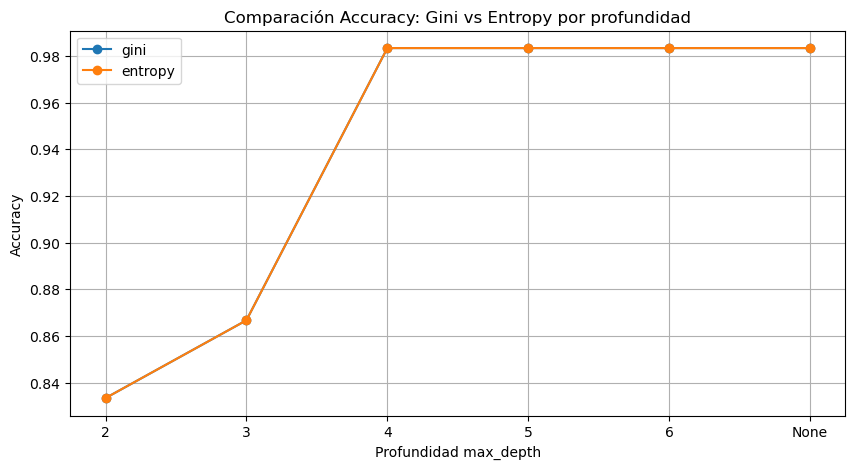

In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
for crit in criterions:
    sub = pd.DataFrame([r for r in results if r['criterion']==crit])
    sub['depth_num'] = sub['max_depth'].apply(lambda x: 7 if x=='None' else int(x))
    sub = sub.sort_values('depth_num')
    plt.plot(sub['depth_num'], sub['accuracy'], marker='o', label=crit)

plt.xticks([2,3,4,5,6,7], ['2','3','4','5','6','None'])
plt.xlabel('Profundidad max_depth')
plt.ylabel('Accuracy')
plt.title('Comparación Accuracy: Gini vs Entropy por profundidad')
plt.legend()
plt.grid(True)
plt.savefig('acc_comparison.png', dpi=200)
plt.show()

## 5. Comparación mediante Reportes de Clasificación

In [9]:
for crit in ['gini','entropy']:
    for d in [2,3,4,None]:
        clf = model_store[(crit,d)]
        y_pred = clf.predict(X_test)
        print(f"\n========== {crit.upper()} depth={d} ==========")
        print(classification_report(y_test, y_pred, target_names=le_drug.classes_, zero_division=0))
        print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")


========== GINI depth=2 ==========
              precision    recall  f1-score   support

       drugA       0.58      1.00      0.74         7
       drugB       0.00      0.00      0.00         5
       drugC       0.00      0.00      0.00         5
       drugX       0.76      1.00      0.86        16
       drugY       1.00      1.00      1.00        27

    accuracy                           0.83        60
   macro avg       0.47      0.60      0.52        60
weighted avg       0.72      0.83      0.77        60

Accuracy: 0.8333

========== GINI depth=3 ==========
              precision    recall  f1-score   support

       drugA       0.88      1.00      0.93         7
       drugB       1.00      0.80      0.89         5
       drugC       0.42      1.00      0.59         5
       drugX       1.00      0.56      0.72        16
       drugY       1.00      1.00      1.00        27

    accuracy                           0.87        60
   macro avg       0.86      0.87      0.8

### Matrices de Confusión para profundidad 4 (óptima)

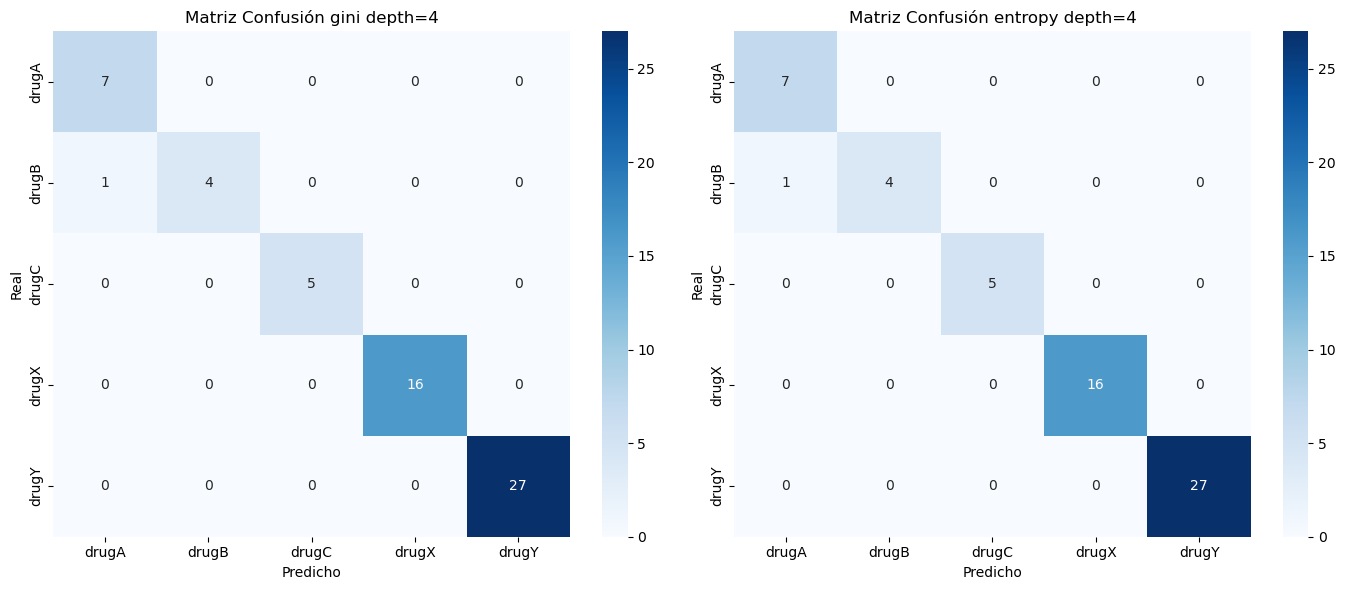

In [10]:
fig, axes = plt.subplots(1,2, figsize=(14,6))
for i, crit in enumerate(['gini','entropy']):
    clf = model_store[(crit,4)]
    y_pred = clf.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', ax=axes[i], cmap='Blues', 
                xticklabels=le_drug.classes_, yticklabels=le_drug.classes_)
    axes[i].set_title(f'Matriz Confusión {crit} depth=4')
    axes[i].set_xlabel('Predicho')
    axes[i].set_ylabel('Real')
plt.tight_layout()
plt.savefig('confusion_depth4.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Visualización del Árbol y Reglas

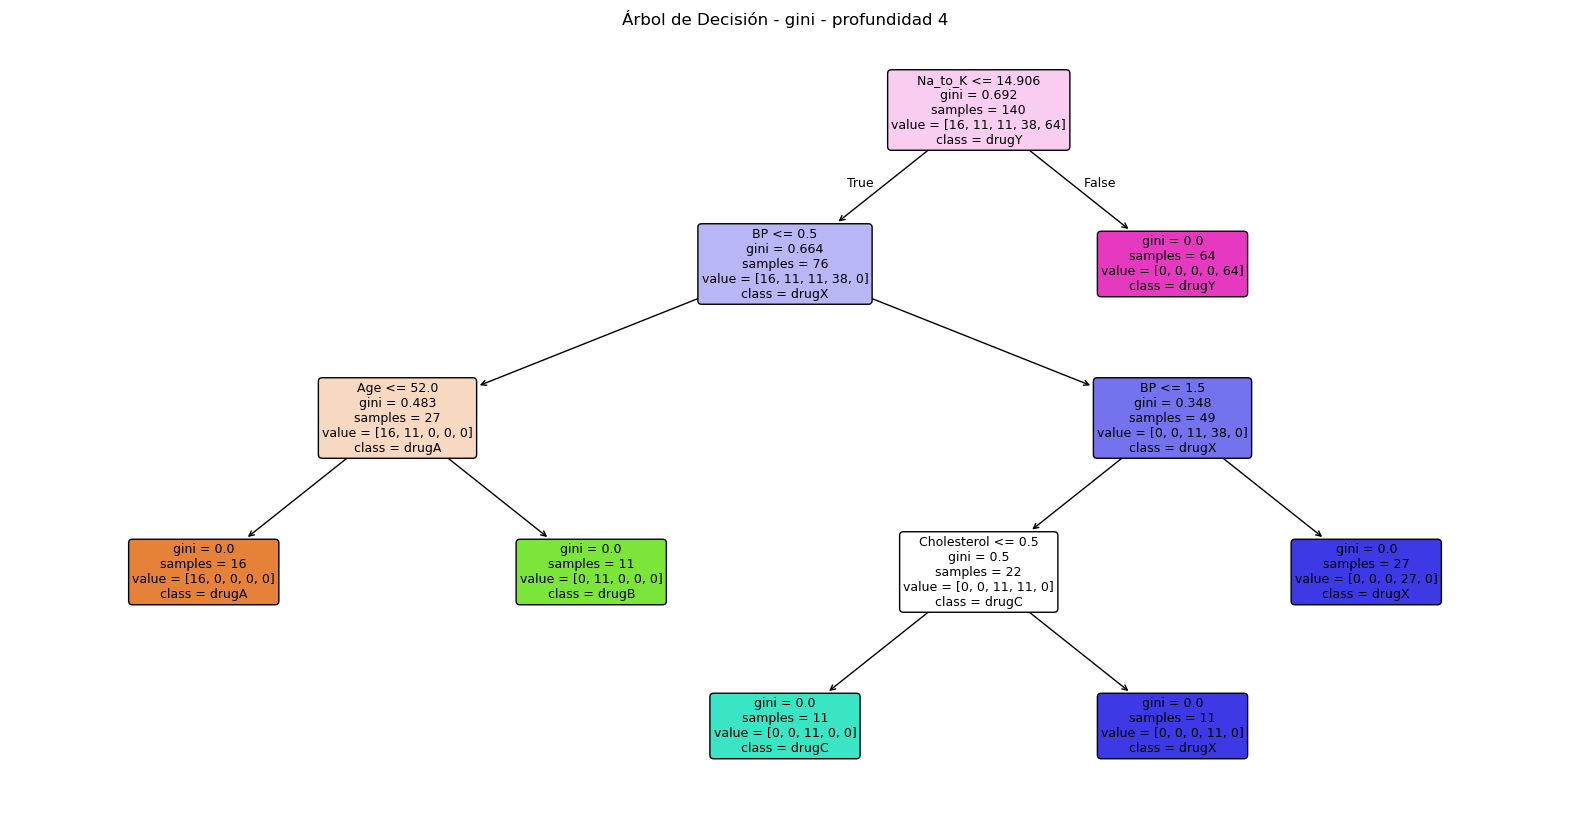

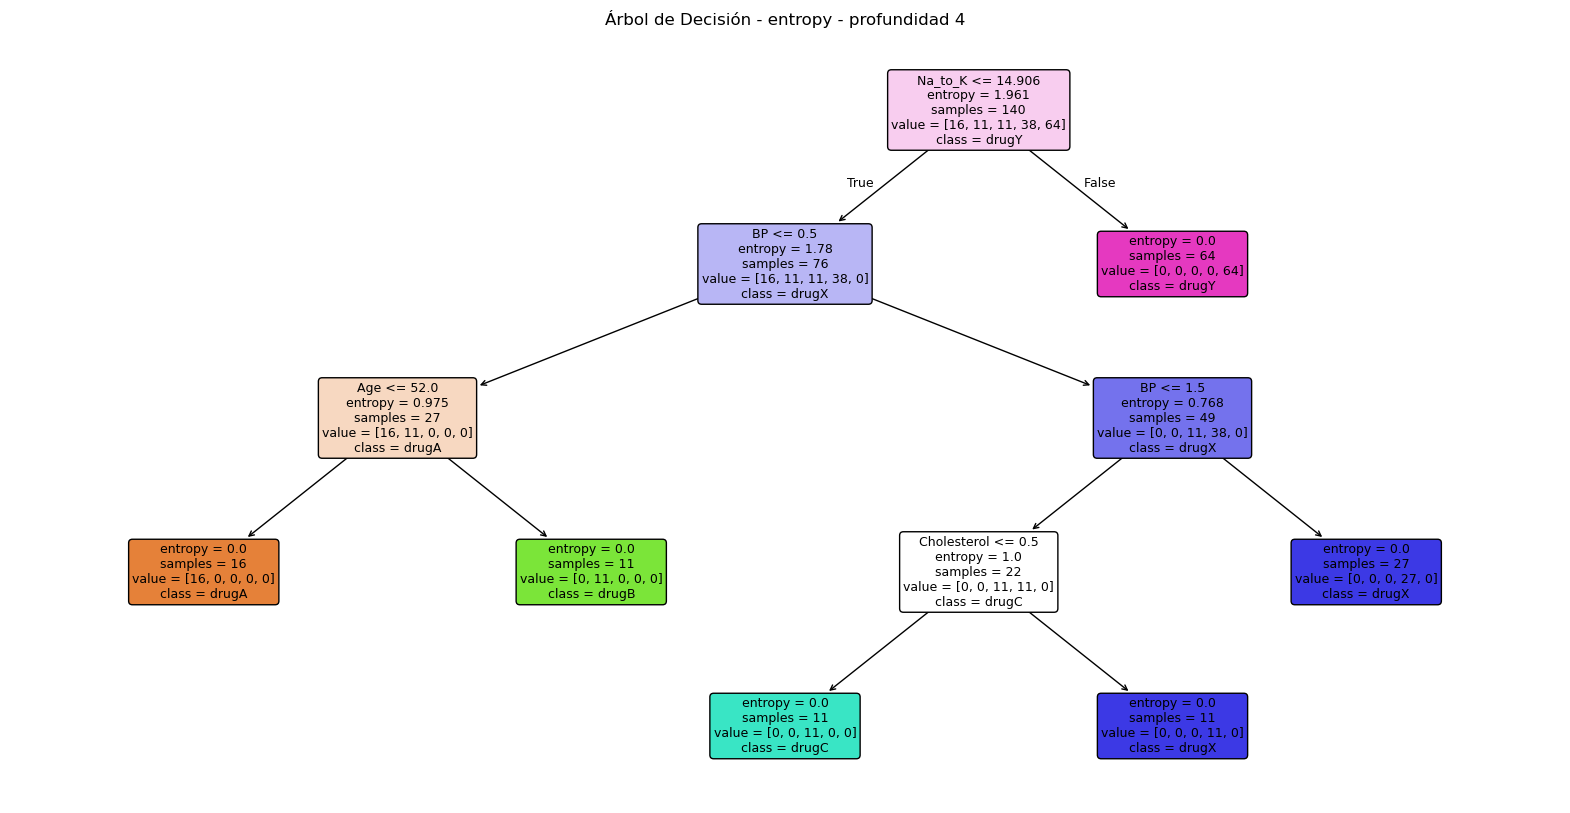


=== REGLAS árbol gini depth=4 ===
|--- Na_to_K <= 14.91
|   |--- BP_enc <= 0.50
|   |   |--- Age <= 52.00
|   |   |   |--- class: 0
|   |   |--- Age >  52.00
|   |   |   |--- class: 1
|   |--- BP_enc >  0.50
|   |   |--- BP_enc <= 1.50
|   |   |   |--- Chol_enc <= 0.50
|   |   |   |   |--- class: 2
|   |   |   |--- Chol_enc >  0.50
|   |   |   |   |--- class: 3
|   |   |--- BP_enc >  1.50
|   |   |   |--- class: 3
|--- Na_to_K >  14.91
|   |--- class: 4


=== REGLAS árbol entropy depth=4 ===
|--- Na_to_K <= 14.91
|   |--- BP_enc <= 0.50
|   |   |--- Age <= 52.00
|   |   |   |--- class: 0
|   |   |--- Age >  52.00
|   |   |   |--- class: 1
|   |--- BP_enc >  0.50
|   |   |--- BP_enc <= 1.50
|   |   |   |--- Chol_enc <= 0.50
|   |   |   |   |--- class: 2
|   |   |   |--- Chol_enc >  0.50
|   |   |   |   |--- class: 3
|   |   |--- BP_enc >  1.50
|   |   |   |--- class: 3
|--- Na_to_K >  14.91
|   |--- class: 4



In [11]:
for crit in ['gini','entropy']:
    clf = model_store[(crit,4)]
    plt.figure(figsize=(20,10))
    plot_tree(clf, feature_names=['Age','Sex','BP','Cholesterol','Na_to_K'],
              class_names=le_drug.classes_, filled=True, rounded=True, fontsize=9)
    plt.title(f'Árbol de Decisión - {crit} - profundidad 4')
    plt.savefig(f'tree_{crit}_depth4.png', dpi=200, bbox_inches='tight')
    plt.show()

# Reglas textuales
for crit in ['gini','entropy']:
    clf = model_store[(crit,4)]
    rules = export_text(clf, feature_names=['Age','Sex_enc','BP_enc','Chol_enc','Na_to_K'])
    print(f"\n=== REGLAS árbol {crit} depth=4 ===\n{rules}")

    # Reglas con mapeo más legible (clases)
    # Nota: Sex_enc 0=F 1=M ; BP_enc 0=HIGH 1=LOW 2=NORMAL ; Chol_enc 0=HIGH 1=NORMAL

## 7. Recomendación para Nuevo Paciente
Datos: age:50, sexo:f, presion arterial:high, colesterol:normal, relacion sodio/potasio:15.302

In [12]:
import warnings
warnings.filterwarnings("ignore")

# Mapeos
print("Sex F ->", le_sex.transform(['F'])[0])
print("BP HIGH ->", le_bp.transform(['HIGH'])[0])
print("Chol NORMAL ->", le_chol.transform(['NORMAL'])[0])

nuevo = [50, le_sex.transform(['F'])[0], le_bp.transform(['HIGH'])[0], le_chol.transform(['NORMAL'])[0], 15.302]
print(f"Vector codificado: {nuevo}")

for crit in ['gini','entropy']:
    clf = model_store[(crit,4)]
    pred_enc = clf.predict([nuevo])[0]
    pred_drug = le_drug.inverse_transform([pred_enc])[0]
    proba = clf.predict_proba([nuevo])[0]
    print(f"\nModelo {crit} depth=4:")
    print(f"  Predicción: {pred_drug}")
    print(f"  Probabilidades: {dict(zip(le_drug.classes_, proba))}")

# Explicación de la decisión siguiendo el árbol:
print("\n--- Trazabilidad de la decisión ---")
print("Na_to_K = 15.302 > 14.91 → va a rama derecha del árbol → clase drugY directamente, con probabilidad 1.0")
print("Independiente de Age, Sex, BP, Cholesterol, la regla principal lo clasifica como drugY")

# Recomendación final
final_model = model_store[('gini',4)]
pred_final = le_drug.inverse_transform(final_model.predict([nuevo]))[0]
print(f"\n>>> RECOMENDACIÓN FINAL: {pred_final} <<<")

Sex F -> 0
BP HIGH -> 0
Chol NORMAL -> 1
Vector codificado: [50, 0, 0, 1, 15.302]

Modelo gini depth=4:
  Predicción: drugY
  Probabilidades: {'drugA': 0.0, 'drugB': 0.0, 'drugC': 0.0, 'drugX': 0.0, 'drugY': 1.0}

Modelo entropy depth=4:
  Predicción: drugY
  Probabilidades: {'drugA': 0.0, 'drugB': 0.0, 'drugC': 0.0, 'drugX': 0.0, 'drugY': 1.0}

--- Trazabilidad de la decisión ---
Na_to_K = 15.302 > 14.91 → va a rama derecha del árbol → clase drugY directamente, con probabilidad 1.0
Independiente de Age, Sex, BP, Cholesterol, la regla principal lo clasifica como drugY

>>> RECOMENDACIÓN FINAL: drugY <<<
